# Piloto CITCA — Análisis Opción E (v2 autocontenido)

Esta versión corrige el error `[Errno 2] No such file or directory`:
- Monta Google Drive forzando refresco (`force_remount=True`) y localiza automáticamente `piloto_citca`.
- Genera el script `analysis_opcion_E.py` directamente en `/tmp/` (evitando fallos de caché de Google Drive en Colab) y guarda también una copia en `opcion_E_bootstrap/`.
- Ejecuta la **Opción E** (conglomerados por artículo, semillas separadas, 20,000 réplicas bootstrap, semilla 2026) sobre `resultados_squad_es/scores` sin tocar los archivos originales.

> **Instrucciones:** No requiere GPU. Solo da clic en **Entorno de ejecución → Ejecutar todas** (o ejecuta las celdas en orden de la 1 a la 6).

In [1]:
import os
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

ROOT = '/content/drive/MyDrive/thesis/piloto_citca'
if not os.path.isdir(ROOT):
    found = None
    for dirpath, dirnames, _ in os.walk('/content/drive/MyDrive'):
        if 'piloto_citca' in dirnames:
            cand = os.path.join(dirpath, 'piloto_citca')
            if os.path.isdir(os.path.join(cand, 'resultados_squad_es')):
                found = cand
                break
    if found:
        ROOT = found
    else:
        raise FileNotFoundError(
            "No se encontró la carpeta 'piloto_citca' con 'resultados_squad_es' dentro de MyDrive. "
            "Verifica que montaste la cuenta de Google correcta."
        )

SCORES = os.path.join(ROOT, 'resultados_squad_es', 'scores')
DATA_DIR = os.path.join(ROOT, 'data', 'squad_es')
OPT_DIR = os.path.join(ROOT, 'opcion_E_bootstrap')
OUT_DIR = os.path.join(OPT_DIR, 'resultados_opcion_E')
os.makedirs(OUT_DIR, exist_ok=True)

n_scores = len([f for f in os.listdir(SCORES) if f.endswith('.csv.gz')]) if os.path.isdir(SCORES) else 0
has_dev = os.path.isfile(os.path.join(DATA_DIR, 'dev.json'))
has_test = os.path.isfile(os.path.join(DATA_DIR, 'test.json'))

print('ROOT    :', ROOT)
print(f'SCORES  : {n_scores} archivos .csv.gz -> {SCORES}')
print(f'DATA_DIR: dev.json={has_dev}, test.json={has_test} -> {DATA_DIR}')
print('OUT_DIR :', OUT_DIR)

assert n_scores > 0, f'No se encontraron archivos .csv.gz en {SCORES}'
assert has_dev and has_test, f'Faltan dev.json o test.json en {DATA_DIR}'

Mounted at /content/drive
ROOT    : /content/drive/MyDrive/thesis/piloto_citca
SCORES  : 60 archivos .csv.gz -> /content/drive/MyDrive/thesis/piloto_citca/resultados_squad_es/scores
DATA_DIR: dev.json=True, test.json=True -> /content/drive/MyDrive/thesis/piloto_citca/data/squad_es
OUT_DIR : /content/drive/MyDrive/thesis/piloto_citca/opcion_E_bootstrap/resultados_opcion_E


## 1. Versiones del entorno (para reproducibilidad en el artículo)

In [2]:
import sys, numpy, pandas, scipy, matplotlib
try:
    import torch, transformers
    ml_info = f' | torch {torch.__version__} | transformers {transformers.__version__}'
except ImportError:
    ml_info = ''

print(
    f'python {sys.version.split()[0]}'
    f' | numpy {numpy.__version__}'
    f' | pandas {pandas.__version__}'
    f' | scipy {scipy.__version__}'
    f' | matplotlib {matplotlib.__version__}'
    f'{ml_info}'
)

python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0 | torch 2.14.1+cu130 | transformers 5.22.1


## 2. Crear script local `analysis_opcion_E.py` (Opción E)

In [4]:
%%writefile /tmp/analysis_opcion_E.py
"""Pilot analysis (Option E): does the configuration chosen in FP32 stay the best after quantization?

Updated from the original analysis.py to implement Option E:
  1. Cluster bootstrap at the article level (--cluster article, using --data-dir dev.json/test.json),
     matching the article-level split of the evaluation data (still supports --cluster passage).
  2. Disjoint seed resampling in the bootstrap (--seed-resample disjoint): seed counts are drawn
     once per replicate and every copy of a seed stays on its original side of each (S, E) split,
     so the same trained run never selects and evaluates simultaneously (still supports --seed-resample original).
  3. Default --boot increased from 2,000 to 20,000 replicates to stabilize CI endpoints near +/-1 F1.
  4. Saves validation/test weighted scores P(lambda) (weighted_scores.csv) and uses unified format
     labels (INT8 (fila), INT4 (fila), INT4-g128) in fig_delta_cf.png.
"""
import argparse
import glob
import hashlib
import itertools
import json
import math
import os

import numpy as np
import pandas as pd
from scipy import stats


def load_scores(folder):
    files = sorted(glob.glob(os.path.join(folder, "*.csv.gz")))
    if not files:
        raise SystemExit(f"no score files in {folder}")
    df = pd.concat([pd.read_csv(f, dtype={"bits": str, "qid": str, "pid": str}) for f in files])
    df["config"] = "lr=" + df.lr.map("{:g}".format) + ",wd=" + df.wd.map("{:g}".format)
    return df


def resolve_data_dir(data_dir):
    if data_dir:
        return data_dir
    for candidate in ("data/squad_es", "../data/squad_es"):
        if os.path.exists(os.path.join(candidate, "dev.json")) and os.path.exists(
            os.path.join(candidate, "test.json")
        ):
            return candidate
    raise SystemExit(
        "could not find dev.json and test.json for --cluster article; "
        "pass --data-dir <folder> (e.g. data/squad_es) or use --cluster passage"
    )


def load_pid_to_article(data_dir):
    """Map split -> {pid: article_title} using the MD5 hash rule from qa_data.py."""
    mapping = {}
    for split in ("dev", "test"):
        path = os.path.join(data_dir, f"{split}.json")
        if not os.path.exists(path):
            raise SystemExit(f"missing {path}; pass --data-dir with dev.json and test.json")
        with open(path, encoding="utf-8") as f:
            raw = json.load(f)
        articles = raw["data"] if isinstance(raw, dict) else raw
        split_map = {}
        for art in articles:
            title = art.get("title", "")
            for par in art["paragraphs"]:
                pid = hashlib.md5(par["context"].encode("utf-8")).hexdigest()[:12]
                split_map[pid] = title
        mapping[split] = split_map
    return mapping


def build_arrays(d, levels, seeds, configs, pid_to_article=None):
    """Per-cluster F1 sums for one model x quantizer: SUM[split] has shape (C, K, L, U)."""
    out = {}
    c_idx = {c: i for i, c in enumerate(configs)}
    k_idx = {k: i for i, k in enumerate(seeds)}
    l_idx = {l: i for i, l in enumerate(levels)}
    for split in ("dev", "test"):
        s = d[d.split == split].copy()
        if pid_to_article is not None:
            s["unit"] = s["pid"].map(pid_to_article[split])
            missing = s["unit"].isna()
            if missing.any():
                sample_missing = sorted(s.loc[missing, "pid"].unique())[:5]
                raise SystemExit(
                    f"found {int(missing.sum())} rows in split '{split}' whose pid is not in "
                    f"data_dir ({sample_missing}); check --data-dir or use --cluster passage"
                )
        else:
            s["unit"] = s["pid"]
        units = sorted(s["unit"].unique())
        uidx = {u: i for i, u in enumerate(units)}
        SUM = np.zeros((len(configs), len(seeds), len(levels), len(units)))
        CNT = np.zeros(len(units))
        ref = s[(s.config == configs[0]) & (s.seed == seeds[0]) & (s.level == levels[0])]
        for u, n in ref.groupby("unit").size().items():
            CNT[uidx[u]] = n
        g = s.groupby(["config", "seed", "level", "unit"]).f1.sum()
        for (c, k, l, u), v in g.items():
            SUM[c_idx[c], k_idx[k], l_idx[l], uidx[u]] = v
        out[split] = (SUM, CNT)
    return out


def means(arr, w=None):
    SUM, CNT = arr
    if w is None:
        return SUM.sum(-1) / CNT.sum()
    return (SUM @ w) / (CNT @ w)


def eval_size(K):
    return max(1, K // 2)


def seed_splits(K):
    """Return all (S, E) index tuples for K-choose-(K - eval_size(K)) seed cross-fitting."""
    splits = []
    for S in itertools.combinations(range(K), K - eval_size(K)):
        E = tuple(k for k in range(K) if k not in S)
        splits.append((S, E))
    return splits


def crossfit(dev, test, lvl):
    """dev, test: (C, K, L) mean F1. Level 0 is FP32."""
    K = dev.shape[1]
    vals = []
    for S, E in seed_splits(K):
        c_fp = int(np.argmax(dev[:, list(S), 0].mean(1)))
        c_b = int(np.argmax(dev[:, list(S), lvl].mean(1)))
        vals.append(test[c_b, list(E), lvl].mean() - test[c_fp, list(E), lvl].mean())
    return float(np.mean(vals))


def naive(test, lvl):
    m = test.mean(1)
    return float(m[:, lvl].max() - m[int(np.argmax(m[:, 0])), lvl])


def split_half_reliability(test, lvl):
    """Average split-half correlation of configuration means across seeds, Spearman-Brown stepped up."""
    K = test.shape[1]
    rs = []
    for A in itertools.combinations(range(K), K // 2):
        B = [k for k in range(K) if k not in A]
        a, b = test[:, list(A), lvl].mean(1), test[:, B, lvl].mean(1)
        if a.std() > 0 and b.std() > 0:
            rs.append(np.corrcoef(a, b)[0, 1])
    if not rs:
        return float("nan")
    r = float(np.mean(rs))
    return 2 * r / (1 + r) if r > -1 else float("nan")


def summarize(dev, test, lvl):
    a, b = test.mean(1)[:, 0], test.mean(1)[:, lvl]
    r_obs = float(np.corrcoef(a, b)[0, 1]) if a.std() > 0 and b.std() > 0 else float("nan")
    rel0, relb = split_half_reliability(test, 0), split_half_reliability(test, lvl)
    r_corr = r_obs / math.sqrt(rel0 * relb) if rel0 > 0 and relb > 0 else float("nan")
    tau = float(stats.kendalltau(a, b).statistic) if len(a) > 1 else float("nan")
    v0, vb = test[:, :, 0].var(1, ddof=1), test[:, :, lvl].var(1, ddof=1)
    var_ratio = float(np.median(vb / np.where(v0 > 0, v0, np.nan)))
    return {
        "delta_cf": crossfit(dev, test, lvl),
        "delta_naive": naive(test, lvl),
        "f1_fp32_best": float(a.max()),
        "f1_b_mean": float(b.mean()),
        "r_obs": r_obs,
        "rel_fp32": rel0,
        "rel_b": relb,
        "r_corr": r_corr,
        "tau": tau,
        "var_ratio": var_ratio,
    }


def bootstrap(arrs, lvl, B, rng, seed_resample="disjoint"):
    """Two-level cluster bootstrap of delta_cf: clusters resampled jointly, then seeds."""
    SUM_dev, CNT_dev = arrs["dev"]
    SUM_test, CNT_test = arrs["test"]
    K = SUM_dev.shape[1]
    U_dev, U_test = CNT_dev.size, CNT_test.size
    p_dev, p_test = np.full(U_dev, 1.0 / U_dev), np.full(U_test, 1.0 / U_test)
    p_seed = np.full(K, 1.0 / K)

    S_dev0 = SUM_dev[:, :, 0, :]      # (C, K, U_dev)
    S_devb = SUM_dev[:, :, lvl, :]    # (C, K, U_dev)
    S_testb = SUM_test[:, :, lvl, :]  # (C, K, U_test)

    splits = seed_splits(K)
    n_splits = len(splits)
    mask_S = np.zeros((n_splits, K), dtype=np.float64)
    mask_E = np.zeros((n_splits, K), dtype=np.float64)
    for si, (S, E) in enumerate(splits):
        mask_S[si, list(S)] = 1.0
        mask_E[si, list(E)] = 1.0

    chunk = 2000
    out = np.empty(B, dtype=np.float64)
    for start in range(0, B, chunk):
        m = min(chunk, B - start)
        w_dev = rng.multinomial(U_dev, p_dev, size=m).astype(np.float64)
        w_test = rng.multinomial(U_test, p_test, size=m).astype(np.float64)

        dev0 = np.einsum("cku,mu->mck", S_dev0, w_dev) / (w_dev @ CNT_dev)[:, None, None]
        devb = np.einsum("cku,mu->mck", S_devb, w_dev) / (w_dev @ CNT_dev)[:, None, None]
        testb = np.einsum("cku,mu->mck", S_testb, w_test) / (w_test @ CNT_test)[:, None, None]

        if seed_resample == "disjoint":
            sw = rng.multinomial(K, p_seed, size=m).astype(np.float64)
            bad = (sw > 0).sum(axis=1) < 2
            while np.any(bad):
                sw[bad] = rng.multinomial(K, p_seed, size=int(bad.sum())).astype(np.float64)
                bad = (sw > 0).sum(axis=1) < 2

            wS = sw[:, None, :] * mask_S[None, :, :]
            wE = sw[:, None, :] * mask_E[None, :, :]
            nS = wS.sum(axis=2)
            nE = wE.sum(axis=2)
            valid = (nS > 0) & (nE > 0)

            sel0 = np.einsum("mck,mpk->mpc", dev0, wS)
            selb = np.einsum("mck,mpk->mpc", devb, wS)
            c_fp = np.argmax(sel0, axis=2)
            c_b = np.argmax(selb, axis=2)

            eval_c = np.einsum("mck,mpk->mpc", testb, wE) / np.where(valid, nE, 1.0)[:, :, None]
            mi = np.arange(m)[:, None]
            pi = np.arange(n_splits)[None, :]
            diffs = eval_c[mi, pi, c_b] - eval_c[mi, pi, c_fp]
            out[start:start + m] = np.where(valid, diffs, 0.0).sum(axis=1) / valid.sum(axis=1)

        elif seed_resample == "original":
            ks = rng.integers(0, K, size=(m, K))
            mi = np.arange(m)[:, None, None]
            ci = np.arange(dev0.shape[1])[None, :, None]
            ks_idx = ks[:, None, :]
            d0 = dev0[mi, ci, ks_idx]
            db = devb[mi, ci, ks_idx]
            tb = testb[mi, ci, ks_idx]

            sel0 = np.einsum("mck,pk->mpc", d0, mask_S)
            selb = np.einsum("mck,pk->mpc", db, mask_S)
            c_fp = np.argmax(sel0, axis=2)
            c_b = np.argmax(selb, axis=2)
            eval_c = np.einsum("mck,pk->mpc", tb, mask_E) / mask_E.sum(axis=1)[None, :, None]
            mi2 = np.arange(m)[:, None]
            pi2 = np.arange(n_splits)[None, :]
            diffs = eval_c[mi2, pi2, c_b] - eval_c[mi2, pi2, c_fp]
            out[start:start + m] = diffs.mean(axis=1)
        else:
            raise ValueError(f"unknown seed_resample: {seed_resample}")

    return out


def decide(est, lo90, hi90, d):
    if lo90 > -d and hi90 < d:
        return "equivalent"
    if est > d and lo90 > 0:
        return "shifted"
    return "inconclusive"


def compute_weighted_table(mean_df):
    """Compute per-config mean/SD across seeds and weighted score P(lambda) on dev and test."""
    rows = []
    for model, dm in mean_df.groupby("model"):
        for cfg, dc in dm.groupby("config"):
            rec = {"model": model, "config": cfg}
            for split_col, tag in (("f1_dev", "dev"), ("f1_test", "test")):
                fp32 = dc[dc.bits == "32"].drop_duplicates("seed")[split_col]
                rec[f"fp32_{tag}_mean"] = float(fp32.mean())
                rec[f"fp32_{tag}_sd"] = float(fp32.std(ddof=1))
                vals = {"fp32": float(fp32.mean())}
                for q in ("gptq", "rtn"):
                    for b in ("8", "4", "4g128"):
                        sub = dc[(dc.quant == q) & (dc.bits == b)][split_col]
                        if len(sub):
                            rec[f"{q}_{b}_{tag}_mean"] = float(sub.mean())
                            rec[f"{q}_{b}_{tag}_sd"] = float(sub.std(ddof=1))
                            vals[f"{q}_{b}"] = float(sub.mean())
                if all(k in vals for k in ("fp32", "gptq_8", "gptq_4", "rtn_4")):
                    rec[f"P_lambda_{tag}"] = (
                        0.20 * vals["fp32"]
                        + 0.20 * vals["gptq_8"]
                        + 0.35 * vals["gptq_4"]
                        + 0.25 * vals["rtn_4"]
                    )
            rows.append(rec)
    return pd.DataFrame(rows)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--scores", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--data-dir", default=None, help="Folder with dev.json and test.json (required for --cluster article)")
    ap.add_argument("--cluster", choices=["article", "passage"], default="article")
    ap.add_argument("--seed-resample", choices=["disjoint", "original"], default="disjoint")
    ap.add_argument("--delta-min", type=float, default=1.0)
    ap.add_argument("--boot", type=int, default=20000)
    ap.add_argument("--seed", type=int, default=2026)
    args = ap.parse_args()

    os.makedirs(args.out, exist_ok=True)
    rng = np.random.default_rng(args.seed)
    df = load_scores(args.scores)

    pid_to_article = None
    if args.cluster == "article":
        args.data_dir = resolve_data_dir(args.data_dir)
        pid_to_article = load_pid_to_article(args.data_dir)

    rows, mean_rows = [], []
    for model in sorted(df.model.unique()):
        dm = df[df.model == model]
        cfg_seeds = dm[dm.quant == "none"].groupby("config").seed.apply(set)
        seeds = sorted(set.intersection(*cfg_seeds))
        configs = sorted(cfg_seeds.index)
        dm = dm[dm.seed.isin(seeds)]
        for quant in sorted(q for q in dm.quant.unique() if q != "none"):
            d = dm[dm.quant.isin(["none", quant])].copy()
            d["level"] = np.where(d.quant == "none", "32", d.bits)
            levels = ["32"] + sorted(
                (l for l in d.level.unique() if l != "32"),
                key=lambda s: (-int(s.split("g")[0]), s),
            )
            arrs = build_arrays(d, levels, seeds, configs, pid_to_article=pid_to_article)
            dev, test = means(arrs["dev"]), means(arrs["test"])
            n_clusters_dev = int(arrs["dev"][1].size)
            n_clusters_test = int(arrs["test"][1].size)
            for ci, c in enumerate(configs):
                for k, s in enumerate(seeds):
                    for li, l in enumerate(levels):
                        mean_rows.append(
                            {
                                "model": model,
                                "quant": quant,
                                "bits": l,
                                "config": c,
                                "seed": s,
                                "f1_dev": dev[ci, k, li],
                                "f1_test": test[ci, k, li],
                            }
                        )
            for li, l in enumerate(levels[1:], start=1):
                res = summarize(dev, test, li)
                bs = bootstrap(arrs, li, args.boot, rng, seed_resample=args.seed_resample)
                lo90, hi90 = np.percentile(bs, [5, 95])
                lo95, hi95 = np.percentile(bs, [2.5, 97.5])
                se = float(bs.std(ddof=1))
                k_needed = (
                    math.ceil(len(seeds) * (1.645 * se / (args.delta_min / 2)) ** 2)
                    if se > 0
                    else len(seeds)
                )
                rows.append(
                    {
                        "model": model,
                        "quant": quant,
                        "bits": l,
                        "K_seeds": len(seeds),
                        "n_configs": len(configs),
                        "n_clusters_dev": n_clusters_dev,
                        "n_clusters_test": n_clusters_test,
                        **res,
                        "ci90_lo": lo90,
                        "ci90_hi": hi90,
                        "ci95_lo": lo95,
                        "ci95_hi": hi95,
                        "boot_se": se,
                        "seeds_for_halfwidth_d/2": k_needed,
                        "decision": decide(res["delta_cf"], lo90, hi90, args.delta_min),
                    }
                )

    summary = pd.DataFrame(rows)
    mean_df = pd.DataFrame(mean_rows)
    weighted_df = compute_weighted_table(mean_df)

    summary.to_csv(os.path.join(args.out, "summary.csv"), index=False)
    mean_df.to_csv(os.path.join(args.out, "config_means.csv"), index=False)
    weighted_df.to_csv(os.path.join(args.out, "weighted_scores.csv"), index=False)
    with open(os.path.join(args.out, "settings.json"), "w") as f:
        json.dump(vars(args), f, indent=2)

    plot(summary, args.delta_min, os.path.join(args.out, "fig_delta_cf.png"))
    cols = [
        "model", "quant", "bits", "K_seeds", "delta_cf", "boot_se",
        "ci90_lo", "ci90_hi", "delta_naive", "r_corr", "decision",
    ]
    print(f"Bootstrap: cluster={args.cluster}, seed_resample={args.seed_resample}, B={args.boot}")
    print(summary[cols].round(2).to_string(index=False))


def _format_label(level):
    if level == "8":
        return "INT8 (fila)"
    if level == "4":
        return "INT4 (fila)"
    if "g" in level:
        b, g = level.split("g")
        return f"INT{b}-g{g}"
    return f"INT{level}"


def plot(summary, d, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    models = list(summary.model.unique())
    fig, axes = plt.subplots(1, len(models), figsize=(4.4 * len(models), 3.3), sharey=True, squeeze=False)
    for ax, m in zip(axes[0], models):
        s = summary[summary.model == m]
        levels = list(dict.fromkeys(s.bits))
        x = np.arange(len(levels))
        ax.axhspan(-d, d, color="0.9", zorder=0)
        ax.axhline(0, color="0.5", lw=0.8)
        for j, q in enumerate(sorted(s.quant.unique())):
            sq = s[s.quant == q].set_index("bits").reindex(levels)
            off = (j - 0.5) * 0.18
            ax.errorbar(
                x + off,
                sq.delta_cf,
                yerr=[sq.delta_cf - sq.ci90_lo, sq.ci90_hi - sq.delta_cf],
                fmt="o",
                capsize=3,
                label=f"{q.upper()} cross-fitted",
            )
            ax.scatter(
                x + off,
                sq.delta_naive,
                marker="x",
                color="0.3",
                zorder=3,
                label="naive (biased)" if j == 0 else None,
            )
        ax.set_xticks(x, [_format_label(l) for l in levels])
        ax.set_title(m)
        ax.set_xlabel("Formato de cuantización")
    axes[0][0].set_ylabel(r"$\hat{\Delta}_{cf}$ (puntos de F1)")
    axes[0][0].legend(fontsize=7, loc="upper left")
    fig.tight_layout()
    fig.savefig(path, dpi=200)


if __name__ == "__main__":
    main()


Overwriting /tmp/analysis_opcion_E.py


## 3. Ejecutar análisis Opción E (20,000 réplicas)
Tarda alrededor de 1 minuto en CPU y guarda los resultados en `opcion_E_bootstrap/resultados_opcion_E/`.

In [5]:
import shutil, subprocess, sys

LOCAL_SCRIPT = '/tmp/analysis_opcion_E.py'
DRIVE_SCRIPT = os.path.join(OPT_DIR, 'analysis_opcion_E.py')
shutil.copyfile(LOCAL_SCRIPT, DRIVE_SCRIPT)
print('Script copiado a:', DRIVE_SCRIPT)

cmd = [
    sys.executable, LOCAL_SCRIPT,
    '--scores', SCORES,
    '--data-dir', DATA_DIR,
    '--cluster', 'article',
    '--seed-resample', 'disjoint',
    '--boot', '20000',
    '--seed', '2026',
    '--out', OUT_DIR,
]
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in proc.stdout:
    print(line, end='')
ret = proc.wait()
if ret != 0:
    raise RuntimeError(f'El análisis terminó con código de error {ret}')
print('\nArchivos guardados en:', OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Script copiado a: /content/drive/MyDrive/thesis/piloto_citca/opcion_E_bootstrap/analysis_opcion_E.py
Bootstrap: cluster=article, seed_resample=disjoint, B=20000
    model quant  bits  K_seeds  delta_cf  boot_se  ci90_lo  ci90_hi  delta_naive  r_corr     decision
biomedico  gptq     8        5      0.00     0.11    -0.18     0.13         0.01    1.01   equivalent
biomedico  gptq     4        5     -0.04     0.23    -0.34     0.39         0.00    1.01   equivalent
biomedico  gptq 4g128        5      0.12     0.21    -0.18     0.50         0.00    1.00   equivalent
biomedico   rtn     8        5     -0.01     0.12    -0.22     0.14         0.00    1.01   equivalent
biomedico   rtn     4        5      0.08     0.37    -0.21     0.97         0.23    1.00   equivalent
biomedico   rtn 4g128        5      0.04     0.21    -0.35     0.34         0.20    0.98   equivalent
  general  gptq     8        5     -0.08     0.17    -0.21     0.30         0.00    1.00   equivalent
  general  gptq     4  

## 4. Revisar Tabla 3, Figura 2 y Tabla 2 (validación y prueba)

=== Tabla 3 (Opción E: artículos, semillas separadas, B=20,000) ===


,model,quant,bits,n_clusters_dev,n_clusters_test,delta_cf,boot_se,ci90_lo,ci90_hi,r_corr,decision
0,biomedico,gptq,8,24,24,0.00,0.11,-0.18,0.13,1.01,equivalent
1,biomedico,gptq,4,24,24,-0.04,0.23,-0.34,0.39,1.01,equivalent
2,biomedico,gptq,4g128,24,24,0.12,0.21,-0.18,0.50,1.00,equivalent
3,biomedico,rtn,8,24,24,-0.01,0.12,-0.22,0.14,1.01,equivalent
4,biomedico,rtn,4,24,24,0.08,0.37,-0.21,0.97,1.00,equivalent
5,biomedico,rtn,4g128,24,24,0.04,0.21,-0.35,0.34,0.98,equivalent
6,general,gptq,8,24,24,-0.08,0.17,-0.21,0.30,1.00,equivalent
7,general,gptq,4,24,24,-0.14,0.40,-0.76,0.58,1.00,equivalent
8,general,gptq,4g128,24,24,-0.07,0.41,-0.77,0.60,1.00,equivalent
9,general,rtn,8,24,24,0.14,0.19,-0.14,0.43,1.00,equivalent


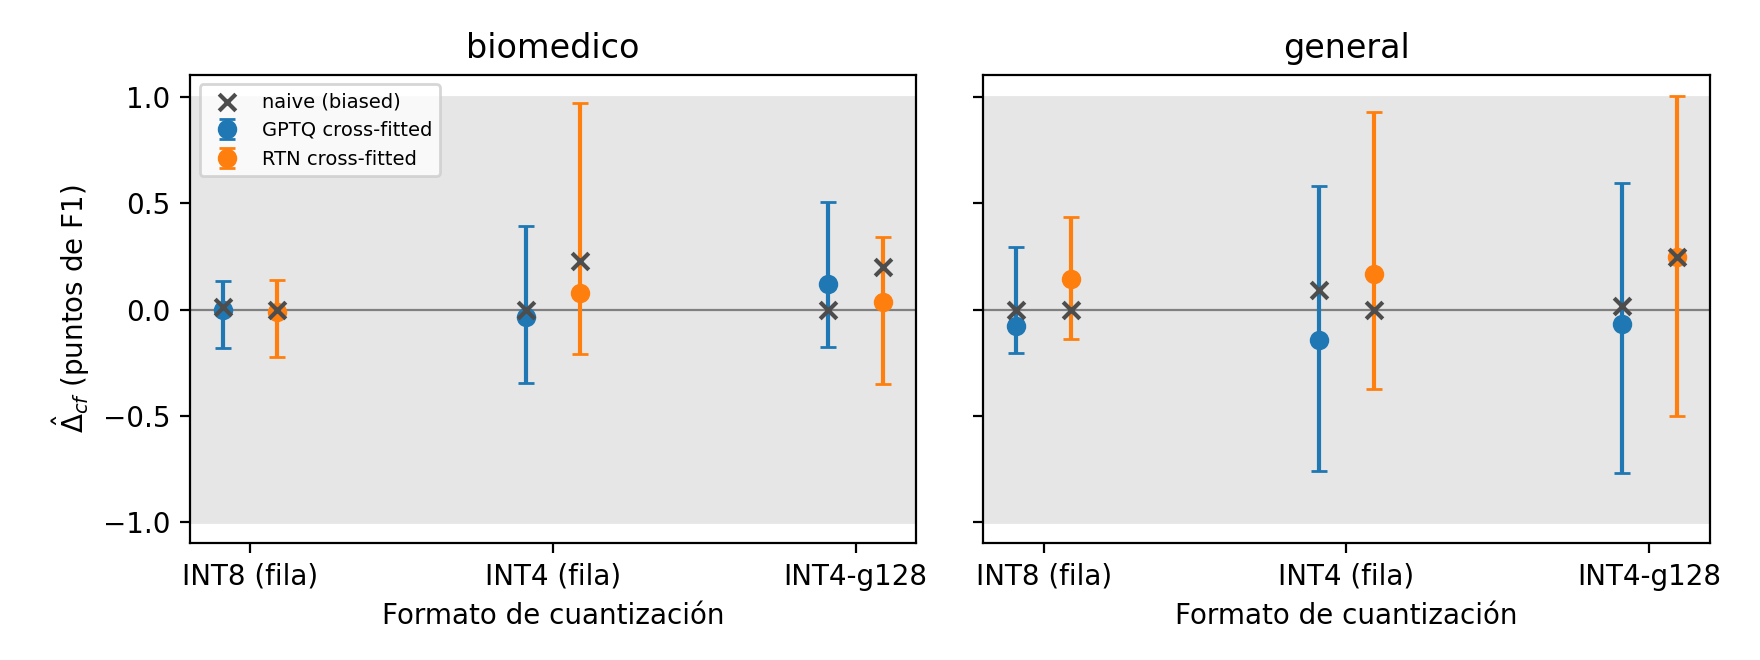

In [6]:
import pandas as pd
from IPython.display import display, Image

summary = pd.read_csv(os.path.join(OUT_DIR, 'summary.csv'), dtype={'bits': str})
cols = ['model', 'quant', 'bits', 'n_clusters_dev', 'n_clusters_test',
        'delta_cf', 'boot_se', 'ci90_lo', 'ci90_hi', 'r_corr', 'decision']
print('=== Tabla 3 (Opción E: artículos, semillas separadas, B=20,000) ===')
display(summary[cols].round(2))

display(Image(os.path.join(OUT_DIR, 'fig_delta_cf.png')))

In [7]:
weighted = pd.read_csv(os.path.join(OUT_DIR, 'weighted_scores.csv'))
print('=== Selección por P(lambda) en validación (Tabla 2 corregida) ===')
dev_cols = ['model', 'config', 'fp32_dev_mean', 'gptq_8_dev_mean', 'rtn_8_dev_mean',
            'gptq_4_dev_mean', 'rtn_4_dev_mean', 'gptq_4g128_dev_mean', 'rtn_4g128_dev_mean',
            'P_lambda_dev']
display(weighted[dev_cols].round(2))

print('=== Ganadoras elegidas en validación evaluadas en prueba ===')
winners = weighted.loc[weighted.groupby('model')['P_lambda_dev'].idxmax()]
test_cols = ['model', 'config', 'fp32_test_mean', 'gptq_8_test_mean', 'rtn_8_test_mean',
             'gptq_4_test_mean', 'rtn_4_test_mean', 'gptq_4g128_test_mean', 'rtn_4g128_test_mean',
             'P_lambda_test']
display(winners[test_cols].round(2))

=== Selección por P(lambda) en validación (Tabla 2 corregida) ===


,model,config,fp32_dev_mean,gptq_8_dev_mean,rtn_8_dev_mean,gptq_4_dev_mean,rtn_4_dev_mean,gptq_4g128_dev_mean,rtn_4g128_dev_mean,P_lambda_dev
0,biomedico,"lr=1e-05,wd=0.001",66.63,66.56,66.53,66.10,61.66,66.61,65.13,65.19
1,biomedico,"lr=1e-05,wd=0.1",66.56,66.58,66.52,66.43,61.85,66.46,65.20,65.34
2,biomedico,"lr=2.5e-05,wd=0.001",69.15,69.19,69.18,68.30,64.87,68.89,68.55,67.79
3,biomedico,"lr=2.5e-05,wd=0.1",69.12,69.16,69.14,68.46,65.11,68.84,68.51,67.89
4,biomedico,"lr=5e-05,wd=0.001",69.70,69.76,69.66,69.13,66.53,69.69,69.04,68.72
5,biomedico,"lr=5e-05,wd=0.1",69.68,69.67,69.72,68.86,66.64,69.25,69.01,68.63
6,general,"lr=1e-05,wd=0.001",61.44,61.48,61.40,60.32,60.40,60.82,60.13,60.80
7,general,"lr=1e-05,wd=0.1",61.72,61.81,61.79,60.55,60.33,61.08,60.46,60.98
8,general,"lr=2.5e-05,wd=0.001",70.11,70.03,70.03,69.34,68.55,69.87,69.25,69.43
9,general,"lr=2.5e-05,wd=0.1",70.21,70.28,70.20,69.71,68.66,69.96,69.29,69.66


=== Ganadoras elegidas en validación evaluadas en prueba ===


,model,config,fp32_test_mean,gptq_8_test_mean,rtn_8_test_mean,gptq_4_test_mean,rtn_4_test_mean,gptq_4g128_test_mean,rtn_4g128_test_mean,P_lambda_test
4,biomedico,"lr=5e-05,wd=0.001",70.47,70.48,70.44,69.64,67.39,70.22,69.20,69.41
11,general,"lr=5e-05,wd=0.1",70.87,70.82,70.78,70.03,69.85,70.46,70.29,70.31
